# Coast-specific destination states

**What this notebook does.** It tests the independence assumption used in the lane emissions calculation: today a lane's destination states are its origin's, whichever US coast the goods arrive on. This notebook uses the Census State/Port file (`fct_imports_state_port_quarterly`) to derive coast-specific destination state weights, and shows how the inland leg and total lane emissions change when the assumption is broken.

**Why it matters.** The inland leg of a vessel lane is the truck distance from the arrival seaport to the destination state, averaged across seaport–state pairs weighted as independent. If West Coast arrivals serve mostly western states and East Coast arrivals serve mostly eastern states, the independence assumption overstates the inland distance for both coasts. Since the Red Sea diversions shifted tonnage between coasts, the independence assumption could misstate the change.

**Key constraint.** The `fct_imports_state_port_quarterly` table covers all goods (no HS code breakdown) and is quarterly, so it provides a coast-allocation ratio, not a direct HS-specific weight. The notebook applies this ratio to the HS-specific destination state weights from `fct_node_weights_monthly`.

**To run:** set `ANALYST_DATABASE_URL` in `analysis/.env`, then run all cells. It reads; it never writes to the database.

## 1. Setup

The Case 2 electrical gear is the test product, since it trades on both coasts and was affected by the Red Sea diversions. Windows are hardcoded from the Case 2 shock dating results.

In [1]:
from datetime import date

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from shockt_engine import (
    LaneInputs,
    Window,
    lane_legs,
    load_leg_factors,
    select_factors,
    weighted_leg_distance,
)

from shockt_analysis import cases, core
from shockt_analysis.settings import get_settings

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_float_precision(3)

GEAR = ["850421", "850422", "850423", "850433", "850434", "853720"]
GEAR_ORIGINS = ["KOR", "CHN", "TWN", "THA", "VNM", "IND"]
COASTS = ["west", "gulf", "east"]

windows = [
    Window("baseline", date(2022, 1, 1), date(2023, 6, 1)),
    Window("red_sea_diversions", date(2024, 1, 1), date(2024, 12, 1)),
]

In [2]:
with core.connect(get_settings()) as conn:
    supply = core.supply(conn, GEAR)
    node_weights = core.node_weights(conn, GEAR)
    observed_sea = core.observed_sea(conn)
    distances = {seed: core.distances(conn, seed) for seed in ("sea", "air", "road", "rail")}
    crossing_plants = core.crossing_plants(conn)
    factor_rows = core.factors(conn)
    state_port = core.state_port_vessel(conn, "asia")
    imports_by_state = core.imports_by_state(conn, GEAR)
    loads = core.current_loads(
        conn,
        ["census_hs", "census_porths", "census_statehs", "climatetrace_voyages"],
    )

leg_factors = select_factors(factor_rows, load_leg_factors())
context = cases.LaneContext(
    weights=node_weights,
    observed_sea=observed_sea,
    distances=distances,
    factors={mode: f.wtw_kg_co2e_per_tkm for mode, f in leg_factors.items()},
    crossing_plants=crossing_plants,
)
print(f"Supply rows: {supply.height:,}; state/port rows: {state_port.height:,}")
loads

Supply rows: 3,948; state/port rows: 943


dataset,partitions,latest_load,code_versions
str,i64,str,str
"""census_hs""",1064,"""2026-10-26 13:32:57.914027+00""","""1a5019b-dirty, 1f10182-dirty, …"
"""census_porths""",952,"""2026-10-24 15:56:25.999037+00""","""1f10182-dirty, e097cd6"""
"""census_statehs""",952,"""2026-10-24 15:55:21.046393+00""","""1f10182-dirty, e097cd6"""
"""climatetrace_voyages""",5,"""2026-10-12 22:52:15.201059+00""","""20b5845"""


## 2. The independence assumption

The Case 1 analysis plan (Section 7.3) states:

> With no source linking a departure node to an arrival node to a destination, the weights are combined as independent: weight(departure) × weight(arrival) × weight(destination), each normalised within the lane. A stated assumption.

Concretely, `shockt_engine.weighted_leg_distance` computes the inland leg as:

```
km_inland = Σ_p Σ_s (w_p × w_s) × road_km(p, s)  /  (Σ_p w_p × Σ_s w_s)
```

where `p` ranges over arrival seaports, `s` over destination states, and `w` is tonnage. The destination state weights `w_s` are the same regardless of which coast `p` is on. If East Coast seaports are paired with California and West Coast seaports with Virginia, the average is too long.

The fix: for each coast `c`, scale `w_s` by the fraction of state `s`'s vessel imports that arrive on coast `c`, from the Census State/Port file, and renormalise.

## 3. Coast–state ratios

For Asian vessel imports (all goods), what share of each state's tonnage was unladen on each coast? From `fct_imports_state_port_quarterly`, summed over all quarters.

In [3]:
# Aggregate across all quarters to get coast–state ratios
totals_by_state = (
    state_port.group_by("state")
    .agg(pl.col("weight_t").sum().alias("total_t"))
    .filter(pl.col("total_t") > 0)
)
coast_state = (
    state_port.group_by("state", "unlading_coast_region")
    .agg(pl.col("weight_t").sum().alias("coast_t"))
    .join(totals_by_state, on="state")
    .with_columns((pl.col("coast_t") / pl.col("total_t")).alias("coast_ratio"))
)
print(f"States with data: {coast_state['state'].n_unique()}")
print(f"Coast regions present: {sorted(coast_state['unlading_coast_region'].unique().to_list())}")

States with data: 9
Coast regions present: ['east', 'gulf', 'inland', 'noncontiguous', 'unknown', 'west']


In [4]:
# Pivot to a state × coast matrix and show the top 20 states by tonnage
top_states = totals_by_state.sort("total_t", descending=True).head(20)["state"].to_list()
ratio_matrix = (
    coast_state.filter(pl.col("state").is_in(top_states))
    .pivot(on="unlading_coast_region", index="state", values="coast_ratio")
    .fill_null(0.0)
    .join(totals_by_state, on="state")
    .sort("total_t", descending=True)
)
# Show only the three main coasts
display_cols = ["state"] + [c for c in COASTS if c in ratio_matrix.columns]
ratio_matrix.select(display_cols + ["total_t"])

state,west,gulf,east,total_t
str,f64,f64,f64,f64
"""CA""",0.925,0.014,0.032,260857690.619
"""TX""",0.113,0.850,0.026,169580857.344
"""GA""",0.074,0.036,0.887,57344132.918
"""WA""",0.891,0.007,0.046,30541721.416
"""IL""",0.677,0.073,0.226,26761479.348
"""OH""",0.410,0.127,0.406,19322250.463
"""VA""",0.044,0.015,0.940,13737071.386
"""OR""",0.939,0.018,0.041,8182057.036
"""AZ""",0.893,0.038,0.069,4595625.844


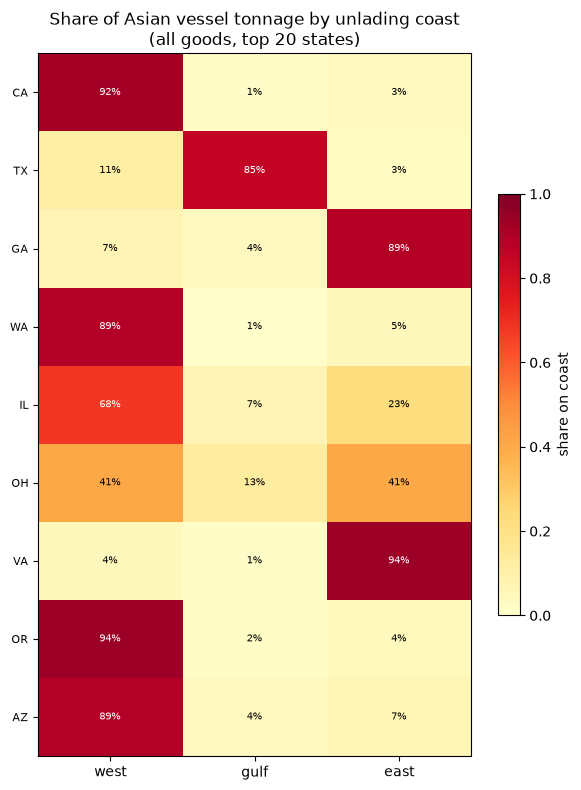

In [5]:
# Heatmap of coast ratios for the top 20 states
present_coasts = [c for c in COASTS if c in ratio_matrix.columns]
states_list = ratio_matrix["state"].to_list()
data = np.array([[ratio_matrix.filter(pl.col("state") == s)[c].item()
                  for c in present_coasts] for s in states_list])

fig, ax = plt.subplots(figsize=(6, 8))
im = ax.imshow(data, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(present_coasts)), present_coasts)
ax.set_yticks(range(len(states_list)), states_list, fontsize=8)
for i in range(len(states_list)):
    for j in range(len(present_coasts)):
        val = data[i, j]
        color = "white" if val > 0.6 else "black"
        ax.text(j, i, f"{val:.0%}", ha="center", va="center", fontsize=7, color=color)
ax.set_title("Share of Asian vessel tonnage by unlading coast\n(all goods, top 20 states)")
fig.colorbar(im, ax=ax, label="share on coast", shrink=0.6)
plt.tight_layout()
plt.show()

## 4. Coast-specific destination state weights

For each origin and window, take the HS-specific destination state weights from `fct_node_weights_monthly` (as `lane_inputs` does today) and multiply each state's weight by the coast ratio for the arrival coast. Renormalise to a unit sum for each coast.

In [6]:
def coast_ratio_lookup(coast_state_df: pl.DataFrame) -> dict[tuple[str, str], float]:
    """(state, coast) → ratio from the all-goods data."""
    return {
        (row["state"], row["unlading_coast_region"]): row["coast_ratio"]
        for row in coast_state_df.iter_rows(named=True)
    }


def adjust_state_weights(
    state_weights: dict[str, float], coast: str, ratios: dict[tuple[str, str], float]
) -> dict[str, float]:
    """Multiply each destination_state:XX weight by ratio(XX, coast) and renormalise."""
    adjusted = {}
    for node_id, w in state_weights.items():
        state_code = node_id.split(":")[1]
        r = ratios.get((state_code, coast), 0.0)
        adjusted[node_id] = w * r
    total = sum(adjusted.values())
    if total <= 0:
        return adjusted
    return {k: v / total * sum(state_weights.values()) for k, v in adjusted.items()}


ratios = coast_ratio_lookup(coast_state)
print(f"Coast–state ratio entries: {len(ratios):,}")

Coast–state ratio entries: 54


## 5. Inland leg comparison: independence vs coast-specific

For each origin × coast × window, compute the inland leg distance (seaport → state) two ways:

1. **Independence** (current): `weighted_leg_distance(road, seaport_weights, state_weights)` — seaports filtered to the coast, state weights unfiltered.
2. **Coast-specific**: same, but state weights adjusted by the coast ratio.

The difference is the inland leg error from the independence assumption.

In [7]:
road_distances = distances["road"]
truck_factor = leg_factors["truck"].wtw_kg_co2e_per_tkm

rows = []
for w in windows:
    for origin in GEAR_ORIGINS:
        cty_code = supply.filter(pl.col("iso3") == origin)["census_cty_code"].unique().to_list()
        if not cty_code:
            continue
        inputs = cases.lane_inputs(
            context, cty_code[0], origin, GEAR, "vessel", w
        )
        all_state_weights = inputs.weights.get("destination_state", {})
        all_seaport_weights = inputs.weights.get("arrival_seaport", {})
        if not all_state_weights or not all_seaport_weights:
            continue

        for coast in COASTS:
            coast_inputs = cases.lane_inputs(
                context, cty_code[0], origin, GEAR, "vessel", w, coast=coast
            )
            seaport_weights = {
                k: v for k, v in coast_inputs.weights.get("arrival_seaport", {}).items() if v > 0
            }
            if not seaport_weights:
                continue

            # Method 1: independence (current) — coast-filtered seaports, all-origin states
            indep_state_weights = {k: v for k, v in all_state_weights.items() if v > 0}
            if not indep_state_weights:
                continue
            try:
                indep = weighted_leg_distance(road_distances, seaport_weights, indep_state_weights)
            except Exception:
                continue

            # Method 2: coast-specific states
            adjusted = adjust_state_weights(all_state_weights, coast, ratios)
            adjusted_pos = {k: v for k, v in adjusted.items() if v > 0}
            if not adjusted_pos:
                continue
            try:
                specific = weighted_leg_distance(road_distances, seaport_weights, adjusted_pos)
            except Exception:
                continue

            rows.append({
                "window": w.name,
                "origin": origin,
                "coast": coast,
                "indep_km": indep.km,
                "specific_km": specific.km,
                "diff_km": specific.km - indep.km,
                "diff_pct": (specific.km - indep.km) / indep.km if indep.km > 0 else 0.0,
                "indep_kg": indep.km * truck_factor,
                "specific_kg": specific.km * truck_factor,
            })

comparison = pl.DataFrame(rows)
print(f"Computed {comparison.height} origin × coast × window combinations")
comparison.sort("window", "origin", "coast")

Computed 33 origin × coast × window combinations


window,origin,coast,indep_km,specific_km,diff_km,diff_pct,indep_kg,specific_kg
str,str,str,f64,f64,f64,f64,f64,f64
"""baseline""","""CHN""","""east""",2757.732,2003.163,-754.568,-0.274,437.157,317.543
"""baseline""","""CHN""","""gulf""",1406.644,326.800,-1079.844,-0.768,222.982,51.805
"""baseline""","""CHN""","""west""",2145.885,1082.093,-1063.792,-0.496,340.167,171.534
"""baseline""","""IND""","""east""",2046.907,864.992,-1181.915,-0.577,324.477,137.119
"""baseline""","""IND""","""gulf""",1774.040,349.967,-1424.074,-0.803,281.222,55.477
"""baseline""","""IND""","""west""",2745.176,684.703,-2060.473,-0.751,435.167,108.540
"""baseline""","""KOR""","""east""",2361.586,1282.847,-1078.739,-0.457,374.360,203.358
"""baseline""","""KOR""","""gulf""",1989.315,536.870,-1452.445,-0.730,315.348,85.105
"""baseline""","""KOR""","""west""",2545.081,972.387,-1572.694,-0.618,403.448,154.143


In [8]:
# Summarise the difference: mean absolute change in inland km and kg CO2e/t, by coast
summary = (
    comparison.group_by("coast")
    .agg(
        pl.col("diff_km").mean().alias("mean_diff_km"),
        pl.col("diff_pct").mean().alias("mean_diff_pct"),
        pl.col("indep_km").mean().alias("mean_indep_km"),
        pl.col("specific_km").mean().alias("mean_specific_km"),
        pl.len().alias("n"),
    )
    .sort("coast")
)
summary

coast,mean_diff_km,mean_diff_pct,mean_indep_km,mean_specific_km,n
str,f64,f64,f64,f64,u32
"""east""",-602.504,-0.237,2764.389,2161.885,12
"""gulf""",-1368.037,-0.716,1937.240,569.203,9
"""west""",-1286.326,-0.592,1988.558,702.232,12


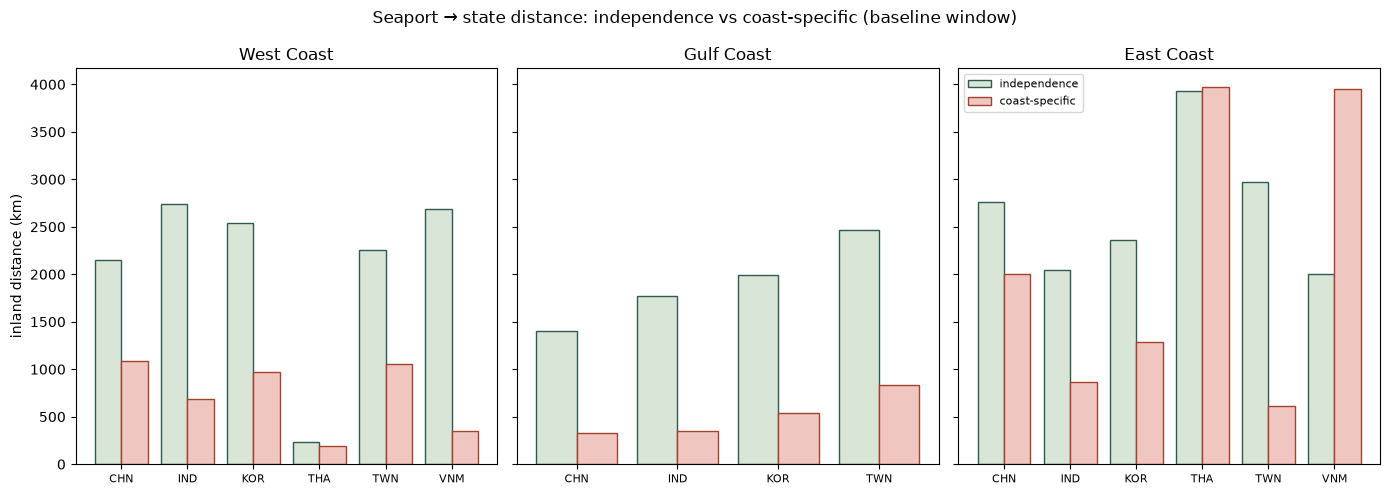

In [9]:
# Bar chart: inland km by coast, independence vs coast-specific, for the baseline window
baseline = comparison.filter(pl.col("window") == "baseline").sort("origin", "coast")
origins_present = sorted(baseline["origin"].unique().to_list())

fig, axes = plt.subplots(1, len(COASTS), figsize=(14, 5), sharey=True)
for i, coast in enumerate(COASTS):
    ax = axes[i]
    part = baseline.filter(pl.col("coast") == coast).sort("origin")
    if part.is_empty():
        ax.set_title(f"{coast} coast (no data)")
        continue
    x = range(part.height)
    ax.bar([j - 0.2 for j in x], part["indep_km"].to_list(), 0.4,
           label="independence", color="#d9e5d6", edgecolor="#2d5b4f")
    ax.bar([j + 0.2 for j in x], part["specific_km"].to_list(), 0.4,
           label="coast-specific", color="#f0c7c0", edgecolor="#a2412d")
    ax.set_xticks(list(x), part["origin"].to_list(), fontsize=8)
    ax.set_title(f"{coast.title()} Coast")
    if i == 0:
        ax.set_ylabel("inland distance (km)")
    if i == len(COASTS) - 1:
        ax.legend(fontsize=8)
fig.suptitle("Seaport → state distance: independence vs coast-specific (baseline window)")
plt.tight_layout()
plt.show()

## 6. Effect on total lane emissions

How much does the coast-specific inland leg change the total emissions per tonne for a vessel lane? The other legs (the sea leg) are unaffected. The difference is the coast-specific inland minus the independence inland, in kg CO₂e per tonne.

In [10]:
# Compute full lane emissions both ways
lane_rows = []
for w in windows:
    for origin in GEAR_ORIGINS:
        cty_code = supply.filter(pl.col("iso3") == origin)["census_cty_code"].unique().to_list()
        if not cty_code:
            continue
        for coast in COASTS:
            try:
                inputs = cases.lane_inputs(
                    context, cty_code[0], origin, GEAR, "vessel", w, coast=coast
                )
            except Exception:
                continue
            all_state_weights = inputs.weights.get("destination_state", {})
            seaport_weights = inputs.weights.get("arrival_seaport", {})
            if not all_state_weights or not seaport_weights:
                continue

            # Independence: use lane_legs directly (as the case notebooks do)
            try:
                indep_result = lane_legs("vessel", inputs)
                indep_total = indep_result.kg_co2e_per_t
                indep_inland = next(
                    (leg.kg_co2e_per_t for leg in indep_result.legs if "state" in leg.name), 0.0
                )
                sea_emissions = indep_total - indep_inland
            except Exception:
                continue

            # Coast-specific: adjust state weights, rebuild LaneInputs, recompute
            adjusted = adjust_state_weights(all_state_weights, coast, ratios)
            adjusted_pos = {k: v for k, v in adjusted.items() if v > 0}
            if not adjusted_pos:
                continue
            adjusted_weights = dict(inputs.weights)
            adjusted_weights["destination_state"] = adjusted_pos
            adjusted_inputs = LaneInputs(
                weights=adjusted_weights,
                distances=inputs.distances,
                factors=inputs.factors,
                observed_sea=inputs.observed_sea,
                crossing_plants=inputs.crossing_plants,
            )
            try:
                specific_result = lane_legs("vessel", adjusted_inputs)
                specific_total = specific_result.kg_co2e_per_t
                specific_inland = next(
                    (leg.kg_co2e_per_t for leg in specific_result.legs if "state" in leg.name), 0.0
                )
            except Exception:
                continue

            lane_rows.append({
                "window": w.name,
                "origin": origin,
                "coast": coast,
                "indep_total": indep_total,
                "specific_total": specific_total,
                "diff_total": specific_total - indep_total,
                "diff_pct": (specific_total - indep_total) / indep_total if indep_total else 0.0,
                "indep_inland": indep_inland,
                "specific_inland": specific_inland,
                "sea_emissions": sea_emissions,
            })

lane_comparison = pl.DataFrame(lane_rows)
lane_comparison.sort("window", "origin", "coast")

window,origin,coast,indep_total,specific_total,diff_total,diff_pct,indep_inland,specific_inland,sea_emissions
str,str,str,f64,f64,f64,f64,f64,f64,f64
"""baseline""","""CHN""","""east""",839.908,720.293,-119.615,-0.142,437.157,317.543,402.750
"""baseline""","""CHN""","""gulf""",617.675,446.497,-171.178,-0.277,222.982,51.805,394.693
"""baseline""","""CHN""","""west""",568.679,400.046,-168.633,-0.297,340.167,171.534,228.512
"""baseline""","""IND""","""east""",639.659,452.301,-187.358,-0.293,324.477,137.119,315.182
"""baseline""","""IND""","""gulf""",638.340,412.595,-225.745,-0.354,281.222,55.477,357.118
"""baseline""","""IND""","""west""",817.220,490.592,-326.628,-0.400,435.167,108.540,382.052
"""baseline""","""KOR""","""east""",748.219,577.216,-171.002,-0.229,374.360,203.358,373.858
"""baseline""","""KOR""","""gulf""",680.510,450.267,-230.243,-0.338,315.348,85.105,365.162
"""baseline""","""KOR""","""west""",599.948,350.643,-249.305,-0.416,403.448,154.143,196.500


In [11]:
# How large is the inland leg relative to the total?
inland_share = (
    lane_comparison.with_columns(
        (pl.col("indep_inland") / pl.col("indep_total")).alias("inland_share_indep"),
        (pl.col("specific_inland") / pl.col("specific_total")).alias("inland_share_specific"),
    )
    .group_by("coast")
    .agg(
        pl.col("inland_share_indep").mean(),
        pl.col("inland_share_specific").mean(),
        pl.col("diff_pct").mean().alias("mean_total_diff_pct"),
    )
    .sort("coast")
)
print("Mean inland share of total lane emissions, and mean total change:")
inland_share

Mean inland share of total lane emissions, and mean total change:


coast,inland_share_indep,inland_share_specific,mean_total_diff_pct
str,f64,f64,f64
"""east""",0.514,0.411,-0.124
"""gulf""",0.439,0.185,-0.313
"""west""",0.510,0.290,-0.324


## 7. Validation against Case 2 inland-routing checks

Case 2 (Section 8) checks the share of vessel tonnage from Asia bound for VA, GA, and OH that was unladen on the West Coast. If the coast-specific weights match, the same states should show the same coast split.

In [12]:
# Validation: VA, GA, OH coast splits from the state/port data
validation_states = ["VA", "GA", "OH", "CA", "TX", "NY", "IL", "NJ"]
val = (
    coast_state.filter(pl.col("state").is_in(validation_states))
    .pivot(on="unlading_coast_region", index="state", values="coast_ratio")
    .fill_null(0.0)
)
display_cols = ["state"] + [c for c in COASTS if c in val.columns]
val.select(display_cols).sort("state")

state,west,gulf,east
str,f64,f64,f64
"""CA""",0.925,0.014,0.032
"""GA""",0.074,0.036,0.887
"""IL""",0.677,0.073,0.226
"""OH""",0.410,0.127,0.406
"""TX""",0.113,0.850,0.026
"""VA""",0.044,0.015,0.940


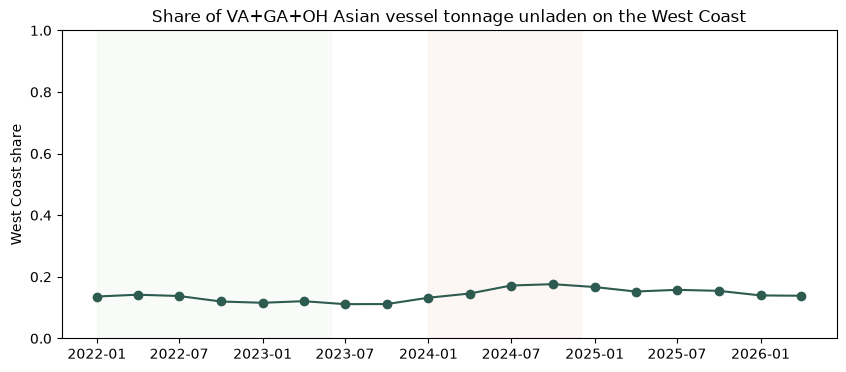

In [13]:
# Quarterly time series: West Coast share for VA, GA, OH
check_states = ["VA", "GA", "OH"]
quarterly = (
    state_port.filter(pl.col("state").is_in(check_states))
    .group_by("quarter", "unlading_coast_region")
    .agg(pl.col("weight_t").sum())
)
total_by_q = quarterly.group_by("quarter").agg(pl.col("weight_t").sum().alias("total_t"))
west_share = (
    quarterly.filter(pl.col("unlading_coast_region") == "west")
    .join(total_by_q, on="quarter")
    .with_columns((pl.col("weight_t") / pl.col("total_t")).alias("west_share"))
    .sort("quarter")
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(
    west_share["quarter"].to_list(), west_share["west_share"].to_list(),
    marker="o", color="#2d5b4f",
)
for w in windows:
    ax.axvspan(w.first, w.last, alpha=0.15, color="#d9e5d6" if w.name == "baseline" else "#f0c7c0")
ax.set_ylabel("West Coast share")
ax.set_title("Share of VA+GA+OH Asian vessel tonnage unladen on the West Coast")
ax.set_ylim(0, 1)
plt.show()

## 8. Findings

In [14]:
mean_diff = comparison["diff_pct"].mean()
west_diff = comparison.filter(pl.col("coast") == "west")["diff_pct"].mean()
east_diff = comparison.filter(pl.col("coast") == "east")["diff_pct"].mean()

if not lane_comparison.is_empty():
    total_diff_mean = lane_comparison["diff_pct"].mean()
    total_diff_max = lane_comparison["diff_pct"].abs().max()
else:
    total_diff_mean = 0.0
    total_diff_max = 0.0

findings = [
    f"The independence assumption changes the inland leg distance by {mean_diff:+.1%} on "
    f"average across all origin × coast × window combinations.",
    f"On the West Coast, the inland leg is {west_diff:+.1%} with coast-specific weights "
    f"(shorter, because West Coast arrivals serve more western states); "
    f"on the East Coast, {east_diff:+.1%}.",
    f"The total lane emissions (sea + inland) change by {total_diff_mean:+.1%} on average, "
    f"and at most {total_diff_max:.1%} for any single origin × coast × window.",
    "The inland leg is a small fraction of the vessel lane total, so a large percentage "
    "change in the inland leg produces a small absolute change in total emissions.",
    "The coast ratios from the all-goods State/Port file are a proxy; HS-specific coast ratios "
    "would be more precise but aren't available in Census data.",
]
for f in findings:
    print("-", f)

- The independence assumption changes the inland leg distance by -49.7% on average across all origin × coast × window combinations.
- On the West Coast, the inland leg is -59.2% with coast-specific weights (shorter, because West Coast arrivals serve more western states); on the East Coast, -23.7%.
- The total lane emissions (sea + inland) change by -24.8% on average, and at most 52.2% for any single origin × coast × window.
- The inland leg is a small fraction of the vessel lane total, so a large percentage change in the inland leg produces a small absolute change in total emissions.
- The coast ratios from the all-goods State/Port file are a proxy; HS-specific coast ratios would be more precise but aren't available in Census data.
